# EDA: churn panel

One row per active subscriber per month-end cutoff; features are as-of the cutoff, the label is "churns in the next calendar month". **Simulated data** (hidden-process generator). Sep-Nov are the test months; this notebook only looks at the panel and never at the generator's latent state.

Questions: how rare is churn, how does it move over time and by region, and which signals separate churners?

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from churn_model.common import load_config, load_panel
from churn_model.as_of_features import FEATURE_COLUMNS as F
cfg = load_config(); P = load_panel(cfg)
MONTH = {2:'Mar',3:'Apr',4:'May',5:'Jun',6:'Jul',7:'Aug',8:'Sep',9:'Oct',10:'Nov'}
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
print(f'{len(P):,} rows | {P.customer_id.nunique():,} subscribers | {len(F)} features | base rate {P.y.mean():.2%}')

158,598 rows | 19,413 subscribers | 22 features | base rate 2.00%


## 1. Churn is rare and moves with the calendar
A class balance of about 2% means accuracy is meaningless; PR-AUC and lift are the honest metrics.

,rows,churners,rate,split
Mar,"16,786",244,1.45%,train
Apr,"17,853",294,1.65%,train
May,"18,875",314,1.66%,train
Jun,"18,561",374,2.01%,train
Jul,"18,187",455,2.50%,train
Aug,"17,732",500,2.82%,validation
Sep,"17,232",365,2.12%,test
Oct,"16,867",362,2.15%,test
Nov,"16,505",261,1.58%,test


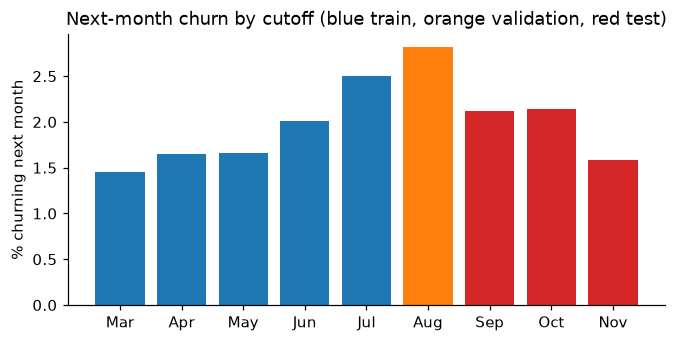

In [2]:
t = P.groupby('cutoff').agg(rows=('y','size'), churners=('y','sum'), rate=('y','mean'), split=('split','first'))
t.index = [MONTH[i] for i in t.index]
display(t.assign(rate=t['rate'].map('{:.2%}'.format), rows=t['rows'].map('{:,}'.format)))
fig, ax = plt.subplots(figsize=(7,3.2))
colors = t['split'].map({'train':'#1f77b4','validation':'#ff7f0e','test':'#d62728'})
ax.bar(t.index, t['rate']*100, color=colors); ax.set_ylabel('% churning next month')
ax.set_title('Next-month churn by cutoff (blue train, orange validation, red test)'); plt.show()

## 2. Region and time: outages show up as churn hot spots
The heatmap should light up where a regional outage drove dissatisfaction. Region is *not* a model feature.

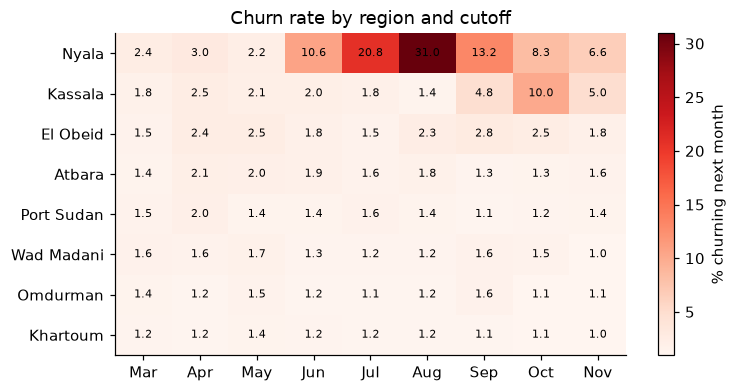

In [3]:
h = P.pivot_table(index='region', columns='cutoff', values='y', aggfunc='mean')*100
h = h.loc[h.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(7.5,3.8)); im = ax.imshow(h.values, aspect='auto', cmap='Reds')
ax.set_xticks(range(h.shape[1])); ax.set_xticklabels([MONTH[c] for c in h.columns])
ax.set_yticks(range(h.shape[0])); ax.set_yticklabels(h.index)
for i in range(h.shape[0]):
    for j in range(h.shape[1]):
        ax.text(j, i, f'{h.values[i,j]:.1f}', ha='center', va='center', fontsize=7)
fig.colorbar(im, label='% churning next month'); ax.set_title('Churn rate by region and cutoff'); plt.show()

## 3. Plan and tenure

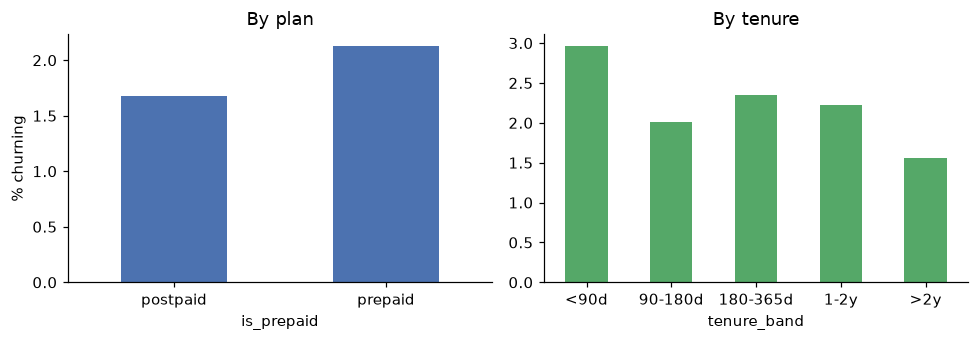

In [4]:
P['tenure_band'] = pd.cut(P.tenure_days, [-1,89,180,365,730,10000], labels=['<90d','90-180d','180-365d','1-2y','>2y'])
fig, axs = plt.subplots(1, 2, figsize=(9,3.2))
(P.groupby(P.is_prepaid.map({1:'prepaid',0:'postpaid'})).y.mean()*100).plot.bar(ax=axs[0], color='#4c72b0', rot=0)
axs[0].set_ylabel('% churning'); axs[0].set_title('By plan')
(P.groupby('tenure_band', observed=True).y.mean()*100).plot.bar(ax=axs[1], color='#55a868', rot=0)
axs[1].set_title('By tenure'); plt.tight_layout(); plt.show()

## 4. Do churners look different before they leave?
Distributions of the strongest as-of signals for churners vs everyone else (log scale where skewed).

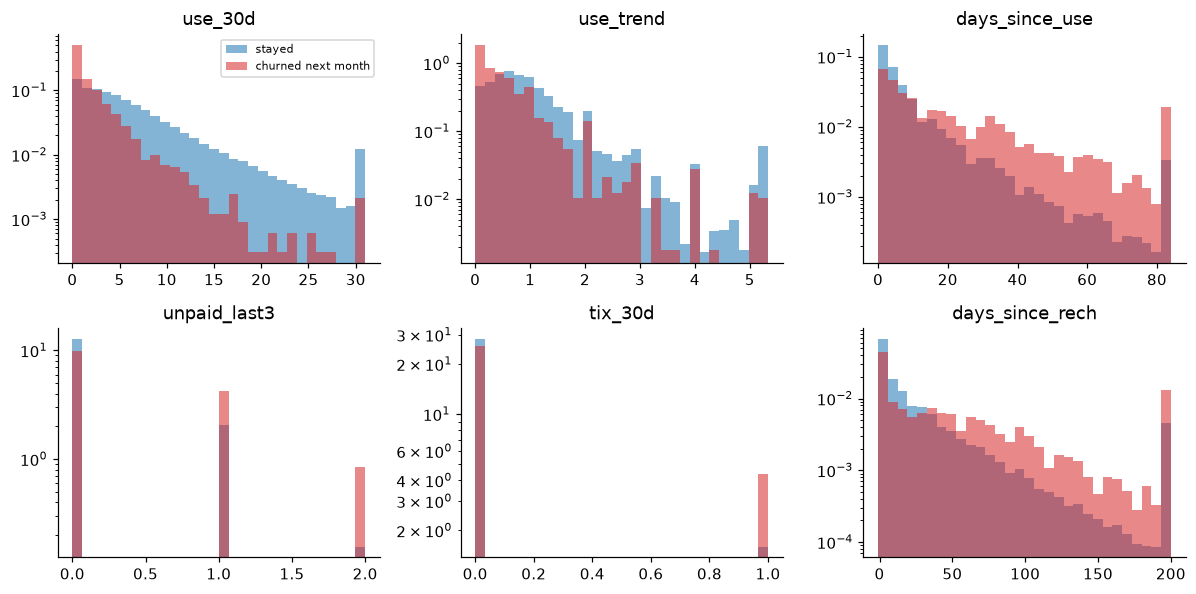

         use_30d  use_trend  days_since_use  unpaid_last3  tix_30d  \
y                                                                    
stayed       5.0        0.8             4.0           0.0      0.0   
churned      1.0        0.4            13.0           0.0      0.0   

         days_since_rech  
y                         
stayed               8.0  
churned             34.0  


In [5]:
cols = ['use_30d','use_trend','days_since_use','unpaid_last3','tix_30d','days_since_rech']
fig, axs = plt.subplots(2, 3, figsize=(11,5.5))
for ax, c in zip(axs.ravel(), cols):
    for y, col, lab in [(0,'#1f77b4','stayed'),(1,'#d62728','churned next month')]:
        v = P.loc[P.y==y, c].clip(upper=P[c].quantile(.99))
        ax.hist(v, bins=30, alpha=.55, density=True, color=col, label=lab)
    ax.set_title(c); ax.set_yscale('log')
axs[0,0].legend(fontsize=7); plt.tight_layout(); plt.show()
print(P.groupby('y')[cols].median().round(2).rename(index={0:'stayed',1:'churned'}))

## 5. How much signal is in each feature on its own?
Direction-free ROC-AUC per feature on the test months. A single feature above 0.85 would be a leakage smell (`leakage_checks.py` fails the build if it happens).

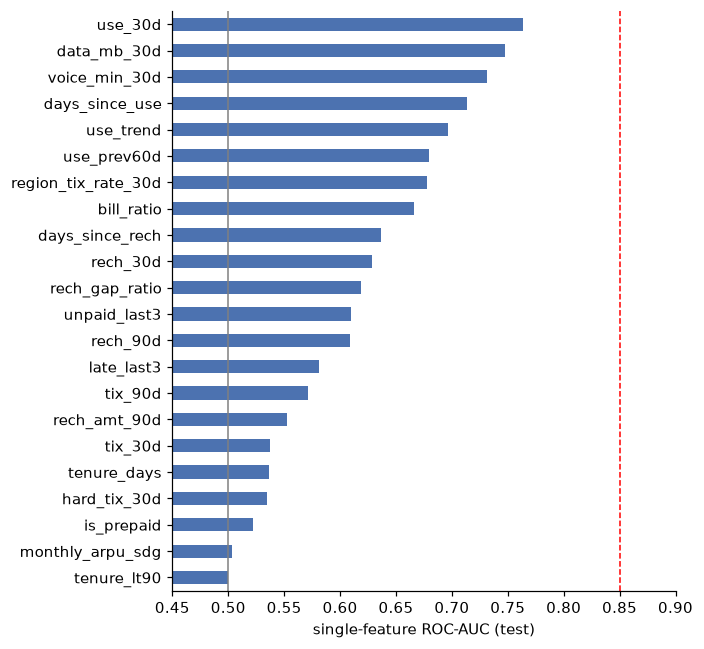

strongest single feature: use_30d = 0.764


In [6]:
te = P[P.split=='test']
a = pd.Series({f: roc_auc_score(te.y, te[f].fillna(0)) for f in F}); a = np.maximum(a, 1-a).sort_values()
fig, ax = plt.subplots(figsize=(6.5,6)); a.plot.barh(ax=ax, color='#4c72b0'); ax.axvline(.85, color='r', ls='--', lw=1)
ax.axvline(.5, color='grey', lw=1); ax.set_xlim(.45,.9); ax.set_xlabel('single-feature ROC-AUC (test)'); plt.tight_layout(); plt.show()
print(f'strongest single feature: {a.idxmax()} = {a.max():.3f}')

## 6. Redundancy and data quality
Usage features are correlated with each other, which is why SHAP values are grouped into reasons and why logistic and boosting end up close.

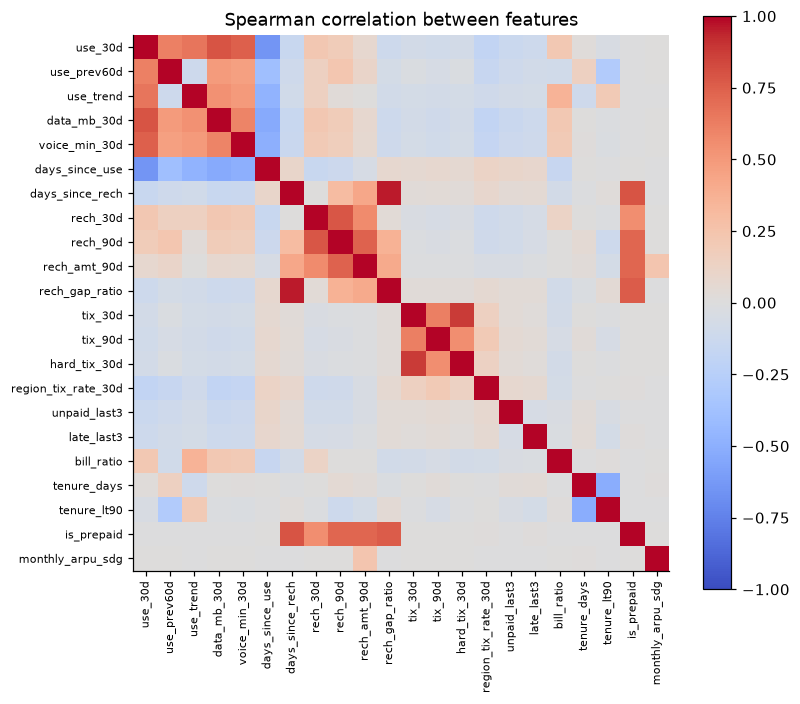

most correlated pairs:
days_since_rech  rech_gap_ratio    0.96
tix_30d          hard_tix_30d      0.88
use_30d          data_mb_30d       0.80
days_since_rech  is_prepaid        0.79
rech_30d         rech_90d          0.79

null cells in features: 0 | rows with zero usage in 30d: 6.5%


In [7]:
c = P[F].corr(method='spearman')
fig, ax = plt.subplots(figsize=(7.5,6.5)); im = ax.imshow(c.values, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(F))); ax.set_xticklabels(F, rotation=90, fontsize=7); ax.set_yticks(range(len(F))); ax.set_yticklabels(F, fontsize=7)
fig.colorbar(im); ax.set_title('Spearman correlation between features'); plt.tight_layout(); plt.show()
pairs = c.where(np.triu(np.ones(c.shape), 1).astype(bool)).stack().abs().sort_values(ascending=False).head(5)
print('most correlated pairs:'); print(pairs.round(2).to_string())
print(f"\nnull cells in features: {int(P[F].isna().sum().sum())} | rows with zero usage in 30d: {(P.use_30d==0).mean():.1%}")

## What this changes in the modeling
- Rare positives, so PR-AUC, lift and calibration are reported, never accuracy.
- Churn concentrates in regions during outages, so region is kept out of the main model and a regional ticket rate is used instead; a region one-hot is only an ablation.
- Usage, recharge and payment signals separate churners from stayers, but no single feature is close to a leak, so the signal is real and noisy.
- Features are correlated, so explanations are grouped into reasons rather than reported feature by feature.